# Bike Sharing Data Analysis

## 1. Introduction

### 1.1 Latar Belakang

Layanan penyewaan sepeda merupakan salah satu alternatif transportasi yang dapat digunakan untuk mendukung mobilitas masyarakat. Dalam pengelolaannya, memahami pola permintaan penyewaan sepeda menjadi hal penting agar penyedia layanan dapat mengoptimalkan ketersediaan sepeda dan meningkatkan efisiensi operasional.

Data penyewaan sepeda dapat memberikan berbagai informasi, seperti pola penggunaan berdasarkan waktu, perbedaan permintaan pada hari kerja dan hari non-kerja, serta hubungan antara kondisi cuaca dan jumlah penyewaan.

Melalui analisis data, pola dan karakteristik permintaan tersebut dapat diidentifikasi sehingga menghasilkan insight yang dapat digunakan sebagai dasar pengambilan keputusan operasional.

### 1.2 Tujuan Analisis

Proyek ini bertujuan untuk menganalisis pola penyewaan sepeda berdasarkan waktu, kondisi cuaca, dan musim selama periode 2011–2012. Hasil analisis diharapkan dapat memberikan gambaran mengenai karakteristik permintaan penyewaan serta menghasilkan rekomendasi untuk mendukung pengelolaan operasional layanan bike sharing.

## 2. Business Understanding

Analisis ini berfokus pada pemahaman pola permintaan penyewaan sepeda berdasarkan beberapa faktor yang terdapat dalam dataset Bike Sharing.

### 2.1 Pertanyaan Bisnis

Berdasarkan tujuan analisis, terdapat tiga pertanyaan bisnis yang akan dijawab:

1. Bagaimana pola rata-rata jumlah penyewaan sepeda per jam pada hari kerja dan hari non-kerja selama Januari 2011–Desember 2012, serta pada jam berapa permintaan mencapai puncaknya?

2. Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kategori kondisi cuaca selama Januari 2011–Desember 2012?

3. Bagaimana perubahan rata-rata jumlah penyewaan sepeda berdasarkan musim dan bulan selama Januari 2011–Desember 2012, serta periode apa yang menunjukkan permintaan tertinggi dan terendah?

### 2.2 Tujuan Bisnis

Berdasarkan pertanyaan bisnis tersebut, analisis dilakukan untuk:

- Mengidentifikasi pola waktu dengan tingkat permintaan penyewaan sepeda tertinggi dan terendah.
- Memahami perbedaan permintaan penyewaan berdasarkan kondisi cuaca.
- Mengidentifikasi pola perubahan permintaan berdasarkan musim dan bulan.
- Menghasilkan rekomendasi operasional berdasarkan karakteristik permintaan penyewaan sepeda.

## 3. Import Libraries

Pada tahap ini, dilakukan import beberapa library Python yang akan digunakan dalam proses pengolahan, analisis, dan visualisasi data.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan DataFrame
pd.set_option('display.max_columns', None)

# Mengatur style visualisasi
sns.set_theme(style="whitegrid")

In [2]:
import pandas as pd

df = pd.read_csv('hour.csv')

df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### 4. Data Wrangling

Data wrangling merupakan proses pengumpulan, pemeriksaan, dan pembersihan data sebelum dilakukan analisis lebih lanjut. Tahapan ini bertujuan untuk memastikan data yang digunakan memiliki kualitas dan struktur yang sesuai dengan kebutuhan analisis.

4.1 Gathering Data

Pada tahap ini, dilakukan proses pengumpulan dan pemuatan dataset Bike Sharing ke dalam DataFrame menggunakan library Pandas. Dataset yang digunakan adalah hour.csv, yang berisi data penyewaan sepeda berdasarkan jam selama periode Januari 2011 hingga Desember 2012.

In [3]:
# Membaca dataset
df = pd.read_csv('hour.csv')

# Menampilkan lima baris pertama
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah data:", df.shape[0])
print("Jumlah fitur:", df.shape[1])

Jumlah baris dan kolom: (17379, 17)
Jumlah data: 17379
Jumlah fitur: 17


In [5]:
# Menampilkan seluruh nama kolom
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

**Hasil Gathering Data**

Berdasarkan proses pemuatan dataset, data Bike Sharing berhasil dibaca menggunakan library Pandas dan disimpan ke dalam DataFrame bernama `df`. Dataset ini terdiri dari 17 kolom yang mencakup informasi waktu penyewaan, kondisi cuaca, serta jumlah pengguna sepeda.

### 4.2 Assessing Data

Pada tahap ini, dilakukan pemeriksaan terhadap kualitas dataset untuk mengidentifikasi permasalahan yang berpotensi memengaruhi proses analisis. Pemeriksaan mencakup struktur data, tipe data, missing values, data duplikat, nilai yang tidak valid, serta outliers.


In [6]:
# Memeriksa informasi umum dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [7]:
#Memeriksa statistik deskriptif
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [8]:
#Memeriksa missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [9]:
#Memeriksa data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 0


In [10]:
#Memeriksa nilai unik
for col in df.columns:
    print(f"{col}: {df[col].nunique()} nilai unik")

instant: 17379 nilai unik
dteday: 731 nilai unik
season: 4 nilai unik
yr: 2 nilai unik
mnth: 12 nilai unik
hr: 24 nilai unik
holiday: 2 nilai unik
weekday: 7 nilai unik
workingday: 2 nilai unik
weathersit: 4 nilai unik
temp: 50 nilai unik
atemp: 65 nilai unik
hum: 89 nilai unik
windspeed: 30 nilai unik
casual: 322 nilai unik
registered: 776 nilai unik
cnt: 869 nilai unik


In [11]:
#Memeriksa nilai yang tidak valid
print("Season:", sorted(df['season'].unique()))
print("Weather:", sorted(df['weathersit'].unique()))
print("Hour:", sorted(df['hr'].unique()))
print("Working Day:", sorted(df['workingday'].unique()))
print("Total Rental negatif:", (df['cnt'] < 0).sum())

Season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Weather: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Hour: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
Working Day: [np.int64(0), np.int64(1)]
Total Rental negatif: 0


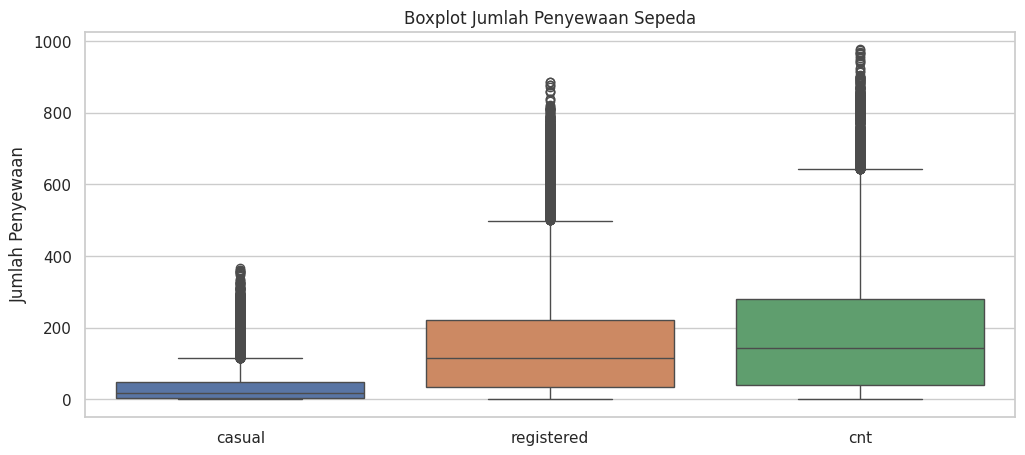

In [12]:
#Memeriksa outliers
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[['casual', 'registered', 'cnt']])
plt.title('Boxplot Jumlah Penyewaan Sepeda')
plt.ylabel('Jumlah Penyewaan')
plt.show()

### Hasil Assessing Data

Berdasarkan pemeriksaan terhadap dataset Bike Sharing, diperoleh beberapa temuan berikut:

1. **Struktur dan tipe data**  
   Dataset terdiri dari 17.379 baris dan 17 kolom dengan penggunaan memori sekitar 2,3 MB. Sebagian besar kolom memiliki tipe data numerik, yaitu 12 kolom bertipe `int64` dan 4 kolom bertipe `float64`. Namun, kolom `dteday` masih bertipe `object`, sehingga perlu dikonversi menjadi tipe `datetime` agar dapat digunakan dalam analisis berdasarkan waktu.

2. **Missing values**  
   Seluruh 17.379 baris memiliki nilai yang terisi pada setiap kolom. Hasil pemeriksaan menunjukkan tidak terdapat missing values pada dataset.

3. **Data duplikat**  
   Pemeriksaan menunjukkan terdapat 0 baris duplikat. Selain itu, kolom `instant` memiliki 17.379 nilai unik, sehingga setiap baris memiliki nomor identifikasi yang berbeda.

4. **Nilai unik dan validitas data**  
   Jumlah nilai unik pada beberapa kolom kategorikal sesuai dengan rentang yang diharapkan. Kolom `season` dan `weathersit` masing-masing memiliki 4 kategori, `mnth` memiliki 12 kategori, `hr` memiliki 24 kategori, dan `weekday` memiliki 7 kategori. Kolom `holiday` dan `workingday` masing-masing memiliki 2 kategori. Pemeriksaan rentang nilai juga menunjukkan bahwa tidak ditemukan nilai negatif pada kolom jumlah penyewaan (`cnt`).

5. **Statistik deskriptif**  
   Kolom `cnt` memiliki rata-rata penyewaan sebanyak 189,46 sepeda per jam, dengan nilai minimum 1 dan maksimum 977. Sementara itu, rata-rata penyewaan pengguna terdaftar (`registered`) adalah 153,79, lebih tinggi dibandingkan pengguna kasual (`casual`) sebesar 35,68.

6. **Outliers**  
   Berdasarkan visualisasi boxplot, terdapat sejumlah titik yang berada di luar batas whisker pada kolom `casual`, `registered`, dan `cnt`. Hal ini menunjukkan adanya nilai penyewaan yang relatif tinggi dibandingkan sebagian besar data. Nilai tersebut belum tentu merupakan kesalahan karena dapat menggambarkan periode dengan permintaan penyewaan yang tinggi.

**Kesimpulan Assessing Data:**  
Secara umum, dataset memiliki kualitas yang cukup baik karena tidak ditemukan missing values, data duplikat, maupun nilai penyewaan negatif. Namun, terdapat satu penyesuaian tipe data yang diperlukan pada kolom `dteday` dan beberapa nilai outlier pada kolom jumlah penyewaan yang perlu ditinjau lebih lanjut. Oleh karena itu, tahap Data Cleaning akan difokuskan pada penyesuaian tipe data dan pemeriksaan kewajaran nilai, tanpa langsung menghapus outlier.

## 4.3 Data Cleaning

Data cleaning merupakan proses memperbaiki atau menangani permasalahan yang ditemukan pada tahap assessing data. Proses ini bertujuan untuk memastikan dataset memiliki format, struktur, dan nilai yang sesuai sehingga dapat digunakan dalam proses analisis.

Berdasarkan hasil assessing data, ditemukan bahwa dataset tidak memiliki missing values dan data duplikat. Namun, kolom `dteday` masih menggunakan tipe data `object` sehingga perlu dikonversi menjadi `datetime`. Selain itu, dilakukan pemeriksaan konsistensi antara jumlah pengguna kasual, pengguna terdaftar, dan total penyewaan. Nilai outlier pada jumlah penyewaan juga akan ditinjau untuk memastikan bahwa nilai tersebut tidak langsung dihapus apabila masih merupakan bagian dari karakteristik permintaan yang valid.

In [13]:
# Menyimpan salinan data asli
df_raw = df.copy()

df_clean = df.copy()

print("Jumlah data sebelum cleaning:", df_clean.shape)

Jumlah data sebelum cleaning: (17379, 17)


In [14]:
# Mengubah tipe data kolom dteday
df_clean['dteday'] = pd.to_datetime(
    df_clean['dteday'],
    errors='coerce'
)

print("Tipe data dteday:", df_clean['dteday'].dtype)
print("Jumlah tanggal tidak valid:", df_clean['dteday'].isna().sum())

Tipe data dteday: datetime64[ns]
Jumlah tanggal tidak valid: 0


In [15]:
# Memeriksa konsistensi jumlah penyewaan
consistent_rentals = (
    df_clean['cnt'] ==
    df_clean['casual'] + df_clean['registered']
)

print("Apakah seluruh total penyewaan konsisten?",
      consistent_rentals.all())

print("Jumlah data tidak konsisten:",
      (~consistent_rentals).sum())

Apakah seluruh total penyewaan konsisten? True
Jumlah data tidak konsisten: 0


In [16]:
# Memeriksa nilai yang tidak valid
invalid_checks = {
    'season': ~df_clean['season'].between(1, 4),
    'yr': ~df_clean['yr'].between(0, 1),
    'mnth': ~df_clean['mnth'].between(1, 12),
    'hr': ~df_clean['hr'].between(0, 23),
    'holiday': ~df_clean['holiday'].between(0, 1),
    'weekday': ~df_clean['weekday'].between(0, 6),
    'workingday': ~df_clean['workingday'].between(0, 1),
    'weathersit': ~df_clean['weathersit'].between(1, 4),
    'temp': ~df_clean['temp'].between(0, 1),
    'atemp': ~df_clean['atemp'].between(0, 1),
    'hum': ~df_clean['hum'].between(0, 1),
    'windspeed': ~df_clean['windspeed'].between(0, 1),
    'casual': df_clean['casual'] < 0,
    'registered': df_clean['registered'] < 0,
    'cnt': df_clean['cnt'] < 0
}

for column, condition in invalid_checks.items():
    print(f"{column}: {condition.sum()} nilai tidak valid")

season: 0 nilai tidak valid
yr: 0 nilai tidak valid
mnth: 0 nilai tidak valid
hr: 0 nilai tidak valid
holiday: 0 nilai tidak valid
weekday: 0 nilai tidak valid
workingday: 0 nilai tidak valid
weathersit: 0 nilai tidak valid
temp: 0 nilai tidak valid
atemp: 0 nilai tidak valid
hum: 0 nilai tidak valid
windspeed: 0 nilai tidak valid
casual: 0 nilai tidak valid
registered: 0 nilai tidak valid
cnt: 0 nilai tidak valid


In [17]:
# Menangani missing values dan duplicate data
print("Total missing values:",
      df_clean.isnull().sum().sum())

print("Total duplicate data:",
      df_clean.duplicated().sum())

Total missing values: 0
Total duplicate data: 0


In [18]:
# Menangani outliers dengan memeriksa statistik jumlah penyewaan setelah cleaning
df_clean[['casual', 'registered', 'cnt']].describe()

,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000
mean,35.676218,153.786869,189.463088
std,49.305030,151.357286,181.387599
min,0.000000,0.000000,1.000000
25%,4.000000,34.000000,40.000000
50%,17.000000,115.000000,142.000000
75%,48.000000,220.000000,281.000000
max,367.000000,886.000000,977.000000


In [19]:
# Menyimpan hasil data cleaning
df = df_clean.copy()

print("Ukuran dataset setelah cleaning:", df.shape)

print("\nInformasi tipe data:")
print(df.dtypes)

print("\nTotal missing values:",
      df.isnull().sum().sum())

print("\nTotal duplicate data:",
      df.duplicated().sum())

Ukuran dataset setelah cleaning: (17379, 17)

Informasi tipe data:
instant                int64
dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

Total missing values: 0

Total duplicate data: 0


### Hasil Data Cleaning

Berdasarkan proses pembersihan data yang telah dilakukan, diperoleh beberapa hasil sebagai berikut:

1. **Perubahan tipe data:** Kolom `dteday` berhasil dikonversi dari tipe data `object` menjadi `datetime64[ns]` agar dapat digunakan untuk analisis berbasis waktu.

2. **Konsistensi data:** Pemeriksaan menunjukkan bahwa jumlah penyewaan (`cnt`) konsisten dengan penjumlahan pengguna kasual (`casual`) dan pengguna terdaftar (`registered`).

3. **Validitas nilai:** Pemeriksaan rentang nilai dilakukan pada variabel kategorikal, variabel cuaca, serta jumlah penyewaan untuk memastikan tidak terdapat nilai di luar rentang yang telah ditentukan.

4. **Missing values dan duplikasi:** Tidak dilakukan penghapusan atau pengisian data karena hasil pemeriksaan menunjukkan tidak terdapat missing values maupun data duplikat.

5. **Outliers:** Nilai ekstrem pada kolom jumlah penyewaan tetap dipertahankan karena belum ditemukan bukti bahwa nilai tersebut merupakan kesalahan pencatatan. Nilai tersebut dapat merepresentasikan kondisi permintaan penyewaan yang tinggi.

**Kesimpulan Data Cleaning:**

Proses pembersihan data difokuskan pada penyesuaian tipe data tanggal dan validasi konsistensi serta rentang nilai. Tidak dilakukan penghapusan observasi karena dataset tidak menunjukkan permasalahan missing values maupun duplikasi. Dataset hasil cleaning kemudian disimpan dalam DataFrame `df` dan siap digunakan untuk tahap Exploratory Data Analysis (EDA).

# 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) merupakan proses eksplorasi data untuk memahami karakteristik, pola, dan hubungan antarvariabel dalam dataset.

Pada tahap ini, dilakukan analisis menggunakan statistik deskriptif, pengelompokan data (grouping), serta agregasi untuk memperoleh informasi yang dapat menjawab pertanyaan bisnis yang telah ditentukan Analisis difokuskan pada pola penyewaan sepeda berdasarkan jam, kondisi cuaca, serta musim dan bulan selama periode Januari 2011 hingga Desember 2012.

### 5.1 Analisis Deskriptif

Pada tahap ini, dilakukan pengecekan kembali gambaran umum mengenai jumlah penyewaan sepeda dan karakteristik pengguna.

In [20]:
# Statistik deskriptif data hasil cleaning
df.describe()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


In [21]:
# Menghitung rata-rata penyewaan berdasarkan jenis pengguna
df[['casual', 'registered', 'cnt']].mean()

,0
casual,35.676218
registered,153.786869
cnt,189.463088


In [22]:
print("Total penyewaan:", df['cnt'].sum())
print("Total pengguna casual:", df['casual'].sum())
print("Total pengguna registered:", df['registered'].sum())

Total penyewaan: 3292679
Total pengguna casual: 620017
Total pengguna registered: 2672662


# Hasil Analisis Deskriptif
Berdasarkan hasil analisis deskriptif terhadap dataset penyewaan sepeda, diperoleh sebanyak 17.379 data dengan total penyewaan mencapai 3.292.679. Dari keseluruhan penyewaan tersebut, terdapat 620.017 pengguna casual dan 2.672.662 pengguna registered.

Rata-rata jumlah penyewaan sepeda (cnt) adalah 189,46 per jam, dengan nilai minimum 1 dan maksimum 977. Sementara itu, rata-rata pengguna casual adalah 35,68 dan pengguna registered mencapai 153,79. Hal ini menunjukkan bahwa pengguna registered mendominasi jumlah penyewaan sepeda dibandingkan pengguna casual.

Dari sisi waktu, dataset mencakup periode 1 Januari 2011 hingga 31 Desember 2012, dengan rata-rata waktu pencatatan berada pada pukul 11.55. Data juga mencakup empat musim, 12 bulan, dan 24 jam dalam sehari.

Untuk kondisi cuaca, rata-rata temperatur (temp) tercatat sebesar 0,497, temperatur terasa (atemp) sebesar 0,476, kelembapan (hum) sebesar 0,627, dan kecepatan angin (windspeed) sebesar 0,190. Seluruh variabel cuaca tersebut menggunakan skala yang telah dinormalisasi.

Kesimpulan awal: pengguna registered memberikan kontribusi terbesar terhadap total penyewaan sepeda, yaitu sekitar 81,18%, sedangkan pengguna casual berkontribusi sekitar 18,82%.

### 5.2 Analisis Business Question 1
Pertanyaan bisnis: Bagaimana pola rata-rata jumlah penyewaan sepeda per jam pada hari kerja dan hari non-kerja selama Januari 2011–Desember 2012, serta pada jam berapa permintaan mencapai puncaknya?

In [23]:
# Menghitung rata-rata penyewaan berdasarkan jam dan hari kerja
hourly_rentals = df.groupby(
    ['hr', 'workingday']
)['cnt'].mean().reset_index()

hourly_rentals.head()

,hr,workingday,cnt
0,0,0,90.800000
1,0,1,36.786290
2,1,0,69.508696
3,1,1,16.552632
4,2,0,53.171053


In [24]:
# Mencari jam dengan rata-rata penyewaan tertinggi
peak_hour = df.groupby('hr')['cnt'].mean().idxmax()

peak_rentals = df.groupby('hr')['cnt'].mean().max()

print("Jam dengan permintaan tertinggi:", peak_hour)
print("Rata-rata penyewaan:", round(peak_rentals, 2))

Jam dengan permintaan tertinggi: 17
Rata-rata penyewaan: 461.45


In [25]:
# Menghitung rata-rata penyewaan berdasarkan hari kerja
workingday_comparison = df.groupby(
    'workingday'
)['cnt'].mean()

workingday_comparison.index = [
    'Non-Working Day' if i == 0 else 'Working Day'
    for i in workingday_comparison.index
]

workingday_comparison

,cnt
Non-Working Day,181.405332
Working Day,193.207754


# Hasil Analisis Business Question 1
Berdasarkan hasil analisis, diketahui bahwa jam dengan permintaan penyewaan sepeda tertinggi adalah pukul 17.00, dengan rata-rata penyewaan mencapai 461,45 sepeda. Hal ini menunjukkan bahwa permintaan penyewaan meningkat pada sore hari, yang kemungkinan berkaitan dengan aktivitas masyarakat setelah menyelesaikan pekerjaan atau kegiatan sehari-hari.
Berdasarkan perbandingan tersebut, rata-rata penyewaan sepeda pada working day lebih tinggi dibandingkan non-working day, dengan selisih sekitar 11,80 penyewaan. Hal ini menunjukkan bahwa penggunaan sepeda pada hari kerja cenderung lebih tinggi dibandingkan hari libur.

### 5.3 Analisis Business Question 2

Pertanyaan bisnis: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kategori kondisi cuaca selama Januari 2011–Desember 2012?

In [26]:
# Menghitung rata-rata penyewaan berdasarkan kondisi cuaca
weather_rentals = df.groupby(
    'weathersit'
)['cnt'].agg(['mean', 'sum', 'count']).reset_index()

weather_rentals

,weathersit,mean,sum,count
0,1,204.869272,2338173,11413
1,2,175.165493,795952,4544
2,3,111.579281,158331,1419
3,4,74.333333,223,3


In [27]:
# Membuat pemetaan kategori cuaca
weather_labels = {
    1: 'Clear / Partly Cloudy',
    2: 'Mist / Cloudy',
    3: 'Light Rain / Snow',
    4: 'Heavy Rain / Snow'
}

weather_rentals['weather_label'] = (
    weather_rentals['weathersit'].map(weather_labels)
)

weather_rentals

,weathersit,mean,sum,count,weather_label
0,1,204.869272,2338173,11413,Clear / Partly Cloudy
1,2,175.165493,795952,4544,Mist / Cloudy
2,3,111.579281,158331,1419,Light Rain / Snow
3,4,74.333333,223,3,Heavy Rain / Snow


In [28]:
# Mencari kondisi cuaca dengan permintaan tertinggi dan terendah
highest_weather = weather_rentals.loc[
    weather_rentals['mean'].idxmax()
]

lowest_weather = weather_rentals.loc[
    weather_rentals['mean'].idxmin()
]

print("Cuaca dengan rata-rata penyewaan tertinggi:")
print(highest_weather['weather_label'])
print(round(highest_weather['mean'], 2))

print("\nCuaca dengan rata-rata penyewaan terendah:")
print(lowest_weather['weather_label'])
print(round(lowest_weather['mean'], 2))

Cuaca dengan rata-rata penyewaan tertinggi:
Clear / Partly Cloudy
204.87

Cuaca dengan rata-rata penyewaan terendah:
Heavy Rain / Snow
74.33


# Hasil Analisis Business Question 2
Berdasarkan hasil analisis, diketahui bahwa kondisi cuaca memiliki perbedaan terhadap rata-rata jumlah penyewaan sepeda. Hasil analisis menunjukkan bahwa penyewaan sepeda tertinggi terjadi ketika kondisi cuaca Clear / Partly Cloudy (cerah atau sedikit berawan), dengan rata-rata penyewaan sebanyak 204,87 sepeda.

Sementara itu, pada kondisi Mist / Cloudy (berkabut atau berawan), rata-rata penyewaan mencapai 175,17 sepeda. Jumlah tersebut mengalami penurunan pada kondisi Light Rain / Snow (hujan ringan atau salju), dengan rata-rata 111,58 sepeda. Adapun rata-rata penyewaan terendah terjadi pada kondisi Heavy Rain / Snow (hujan deras atau salju lebat), yaitu sebesar 74,33 sepeda. Namun, kategori cuaca ini hanya memiliki 3 data pengamatan sehingga hasilnya perlu diinterpretasikan secara hati-hati.

### 5.4 Analisis Business Question 3
Pertanyaan bisnis: Bagaimana perubahan rata-rata jumlah penyewaan sepeda berdasarkan musim dan bulan selama Januari 2011–Desember 2012, serta periode apa yang menunjukkan permintaan tertinggi dan terendah?

In [29]:
# Menghitung rata-rata penyewaan berdasarkan musim
season_rentals = df.groupby(
    'season'
)['cnt'].agg(['mean', 'sum', 'count']).reset_index()

season_labels = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

season_rentals['season_label'] = (
    season_rentals['season'].map(season_labels)
)

season_rentals

,season,mean,sum,count,season_label
0,1,111.114569,471348,4242,Spring
1,2,208.344069,918589,4409,Summer
2,3,236.016237,1061129,4496,Fall
3,4,198.868856,841613,4232,Winter


In [30]:
# Menghitung rata-rata penyewaan berdasarkan bulan
monthly_rentals = df.groupby(
    'mnth'
)['cnt'].mean().reset_index()

monthly_rentals

,mnth,cnt
0,1,94.424773
1,2,112.865026
2,3,155.410726
3,4,187.260960
4,5,222.907258
5,6,240.515278
6,7,231.819892
7,8,238.097627
8,9,240.773138
9,10,222.158511


In [31]:
# Mengetahui musim dan bulan dengan permintaan tertinggi
highest_season = season_rentals.loc[
    season_rentals['mean'].idxmax()
]

lowest_season = season_rentals.loc[
    season_rentals['mean'].idxmin()
]

highest_month = monthly_rentals.loc[
    monthly_rentals['cnt'].idxmax()
]

lowest_month = monthly_rentals.loc[
    monthly_rentals['cnt'].idxmin()
]

print("Musim dengan permintaan tertinggi:",
      highest_season['season_label'])

print("Musim dengan permintaan terendah:",
      lowest_season['season_label'])

print("Bulan dengan permintaan tertinggi:",
      int(highest_month['mnth']))

print("Bulan dengan permintaan terendah:",
      int(lowest_month['mnth']))

Musim dengan permintaan tertinggi: Fall
Musim dengan permintaan terendah: Spring
Bulan dengan permintaan tertinggi: 9
Bulan dengan permintaan terendah: 1


# Hasil Analisis Business Question 3
Berdasarkan hasil analisis, diketahui bahwa rata-rata jumlah penyewaan sepeda mengalami perubahan berdasarkan musim. Musim dengan rata-rata penyewaan tertinggi adalah Fall (musim gugur), dengan rata-rata sebanyak 236,02 sepeda. Sementara itu, rata-rata penyewaan terendah terjadi pada musim Spring (musim semi), yaitu sebesar 111,11 sepeda.

Pada musim lainnya, rata-rata penyewaan sepeda tercatat sebesar 208,34 sepeda pada Summer (musim panas) dan 198,87 sepeda pada Winter (musim dingin). Hasil ini menunjukkan bahwa musim memiliki keterkaitan dengan tingkat permintaan penyewaan sepeda. Selain berdasarkan musim, analisis juga dilakukan berdasarkan bulan. Hasilnya menunjukkan bahwa rata-rata penyewaan tertinggi terjadi pada bulan September (bulan ke-9), yaitu sebesar 240,77 sepeda. Sebaliknya, rata-rata penyewaan terendah terjadi pada bulan Januari (bulan ke-1), dengan rata-rata sebanyak 94,42 sepeda.

# 6. Visualization & Explanatory Analysis

Visualization & Explanatory Analysis merupakan tahap penyajian hasil eksplorasi data dalam bentuk visualisasi agar pola, perbandingan, dan hubungan antarvariabel lebih mudah dipahami.

Visualisasi dibuat berdasarkan tiga pertanyaan bisnis yang telah ditentukan pada tahap Business Understanding. Setiap visualisasi dilengkapi dengan interpretasi untuk menjelaskan insight yang diperoleh dan implikasinya terhadap pengelolaan layanan penyewaan sepeda.

### 6.1 Visualisasi Business Question 1
Pertanyaan bisnis: Bagaimana pola rata-rata jumlah penyewaan sepeda per jam pada hari kerja dan hari non-kerja selama Januari 2011–Desember 2012, serta pada jam berapa permintaan mencapai puncaknya?

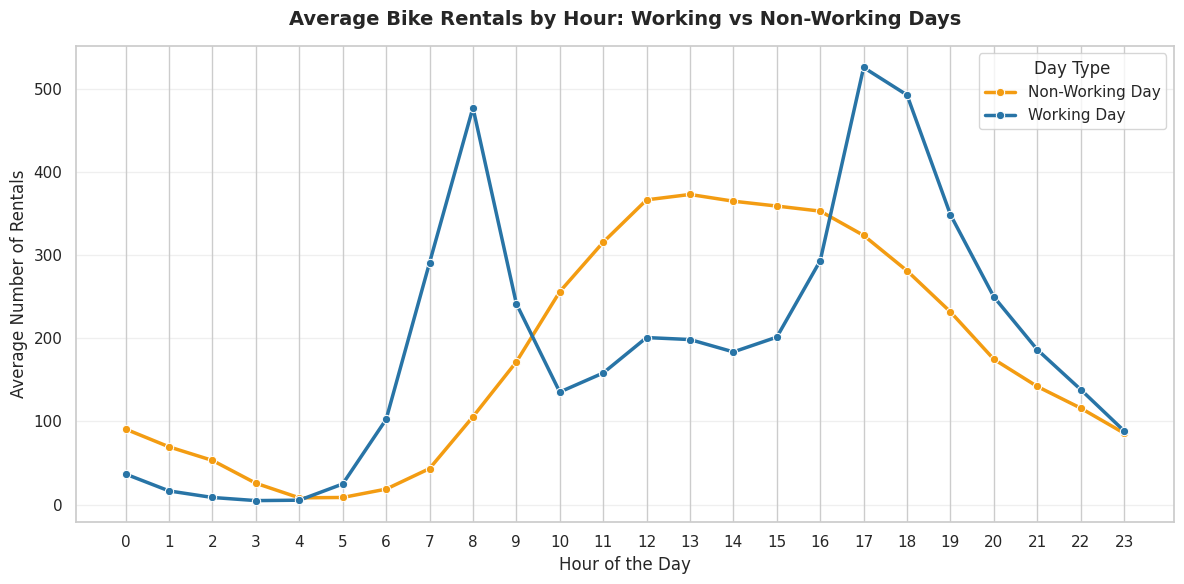

In [32]:
hourly_plot = hourly_rentals.copy()

hourly_plot['day_type'] = hourly_plot['workingday'].map({
    0: 'Non-Working Day',
    1: 'Working Day'
})

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_plot,
    x='hr',
    y='cnt',
    hue='day_type',
    marker='o',
    linewidth=2.5,
    palette=['#F39C12', '#2874A6']
)

plt.title(
    'Average Bike Rentals by Hour: Working vs Non-Working Days',
    fontsize=14,
    fontweight='bold',
    pad=15
)
plt.xlabel('Hour of the Day')
plt.ylabel('Average Number of Rentals')
plt.xticks(range(24))
plt.legend(title='Day Type')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Explanatory Analysis Question 1
Berdasarkan hasil visualisasi, dapat disimpulkan bahwa pola penyewaan sepeda berbeda antara hari kerja dan hari non-kerja. Pada hari kerja, permintaan tertinggi terjadi pada pukul 17.00, yang kemungkinan berkaitan dengan aktivitas masyarakat setelah jam kerja. Sementara itu, pada hari non-kerja, permintaan tertinggi terjadi sekitar pukul 13.00, yang menunjukkan kecenderungan penggunaan sepeda pada siang hari.

Temuan ini dapat dimanfaatkan untuk membantu pengelolaan dan distribusi ketersediaan sepeda berdasarkan waktu. Pada hari kerja, ketersediaan sepeda perlu diperhatikan terutama pada pagi dan sore hari, sedangkan pada hari non-kerja perlu diprioritaskan pada periode menjelang siang hingga sore hari.

### 6.2 Visualisasi Business Question 2
Pertanyaan bisnis: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kategori kondisi cuaca selama Januari 2011–Desember 2012?

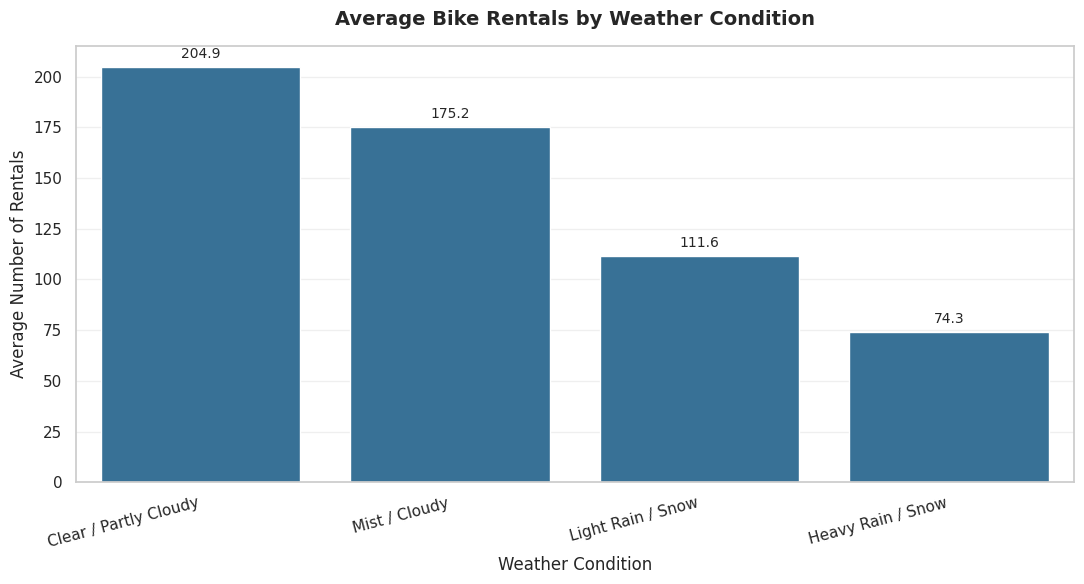

In [33]:
weather_plot = weather_rentals.sort_values(
    'mean', ascending=False
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=weather_plot,
    x='weather_label',
    y='mean',
    color='#2874A6'
)

# Menambahkan label angka
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f',
        padding=4,
        fontsize=10
    )

plt.title(
    'Average Bike Rentals by Weather Condition',
    fontsize=14,
    fontweight='bold',
    pad=15
)
plt.xlabel('Weather Condition')
plt.ylabel('Average Number of Rentals')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Explanatory Analysis Question 2
Berdasarkan hasil visualisasi, dapat disimpulkan bahwa kondisi cuaca memiliki hubungan dengan tingkat penyewaan sepeda. Rata-rata penyewaan tertinggi terjadi pada kondisi Clear / Partly Cloudy, sedangkan rata-rata terendah terjadi pada kondisi Heavy Rain / Snow. Secara keseluruhan, grafik menunjukkan kecenderungan bahwa semakin buruk kondisi cuaca, semakin rendah rata-rata jumlah penyewaan sepeda.

Hasil analisis ini dapat menjadi pertimbangan dalam pengelolaan ketersediaan sepeda dan perencanaan operasional. Pada kondisi cuaca cerah, penyedia layanan dapat mempersiapkan ketersediaan sepeda yang lebih banyak untuk mengantisipasi tingginya permintaan. Sebaliknya, pada kondisi cuaca buruk, jumlah sepeda yang disediakan dapat disesuaikan dengan perkiraan permintaan.

### 6.3 Visualisasi Business Question 3
Pertanyaan bisnis: Bagaimana perubahan rata-rata jumlah penyewaan sepeda berdasarkan musim dan bulan selama Januari 2011–Desember 2012, serta periode apa yang menunjukkan permintaan tertinggi dan terendah?

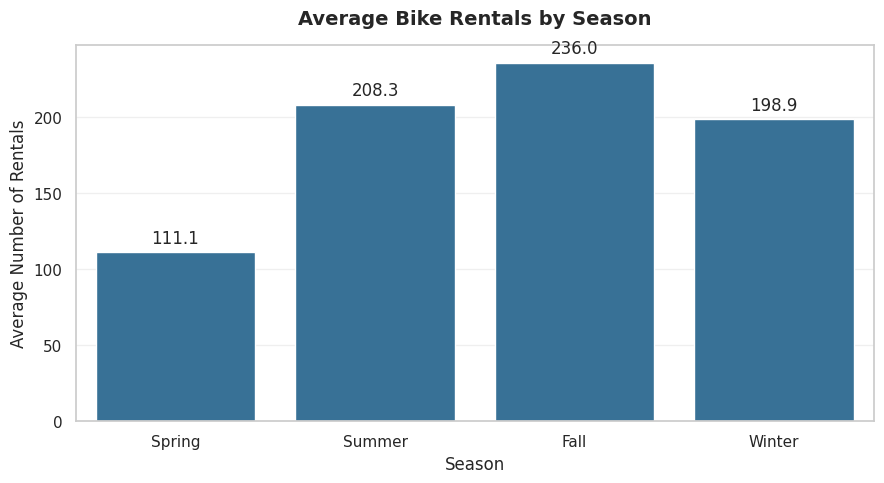

In [34]:
# Mengurutkan data berdasarkan musim
season_plot = season_rentals.sort_values('season')

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=season_plot,
    x='season_label',
    y='mean',
    color='#2874A6'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f',
        padding=4
    )

plt.title(
    'Average Bike Rentals by Season',
    fontsize=14,
    fontweight='bold',
    pad=15
)
plt.xlabel('Season')
plt.ylabel('Average Number of Rentals')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

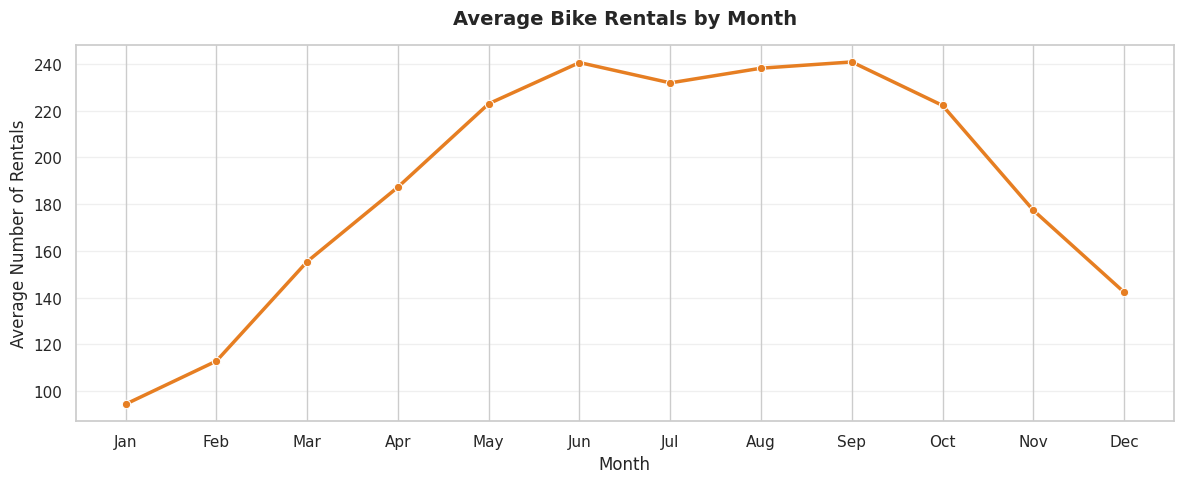

In [35]:
# Membuat label bulan
month_labels = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_plot = monthly_rentals.copy()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_plot,
    x='mnth',
    y='cnt',
    marker='o',
    linewidth=2.5,
    color='#E67E22'
)

plt.title(
    'Average Bike Rentals by Month',
    fontsize=14,
    fontweight='bold',
    pad=15
)
plt.xlabel('Month')
plt.ylabel('Average Number of Rentals')
plt.xticks(range(1, 13), month_labels)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Explanatory Analysis Question 3
Berdasarkan kedua hasil visualisasi, dapat disimpulkan bahwa rata-rata jumlah penyewaan sepeda mengalami perubahan berdasarkan musim dan bulan. Berdasarkan musim, Fall menjadi periode dengan rata-rata penyewaan tertinggi, sedangkan Spring menjadi periode dengan rata-rata penyewaan terendah. Sementara itu, berdasarkan bulan, September merupakan bulan dengan permintaan tertinggi dan Januari merupakan bulan dengan permintaan terendah.

Pola tersebut menunjukkan bahwa aktivitas penyewaan sepeda cenderung meningkat dari awal tahun hingga mencapai puncaknya pada periode pertengahan hingga akhir tahun, kemudian mengalami penurunan menjelang akhir tahun. Hasil analisis ini dapat dimanfaatkan sebagai bahan pertimbangan dalam perencanaan operasional dan pengelolaan ketersediaan sepeda. Penyedia layanan dapat mempersiapkan jumlah sepeda yang lebih banyak menjelang periode dengan permintaan tinggi, khususnya pada bulan Juni hingga September, serta menyesuaikan ketersediaan sepeda ketika permintaan mulai menurun.

### 6.4 Rangkuman Visualization dan Explanatory Analysis
Berdasarkan ketiga visualisasi yang telah dibuat, terdapat tiga aspek utama yang dianalisis untuk memahami pola dan karakteristik permintaan penyewaan sepeda selama Januari 2011–Desember 2012:

1\. **Pola penyewaan berdasarkan jam dan jenis hari:** Visualisasi *line chart* digunakan untuk membandingkan rata-rata jumlah penyewaan sepeda pada *working day* dan *non-working day* berdasarkan jam. Hasil visualisasi menunjukkan bahwa pada hari kerja, permintaan tertinggi terjadi pada pukul **17.00**, sedangkan pada hari non-kerja mencapai puncaknya sekitar pukul **13.00**. Pola ini menunjukkan bahwa waktu penyewaan pada hari kerja cenderung berkaitan dengan aktivitas sebelum dan setelah jam kerja, sedangkan pada hari non-kerja lebih terkonsentrasi pada siang hari.

2\. **Pola penyewaan berdasarkan kondisi cuaca:** Visualisasi *bar chart* digunakan untuk membandingkan rata-rata jumlah penyewaan sepeda berdasarkan empat kategori kondisi cuaca. Hasil visualisasi menunjukkan bahwa kondisi *Clear / Partly Cloudy* memiliki rata-rata penyewaan tertinggi sebesar **204,9 sepeda**, sedangkan *Heavy Rain / Snow* memiliki rata-rata terendah sebesar **74,3 sepeda**. Hal ini menunjukkan bahwa kondisi cuaca yang lebih baik cenderung diikuti oleh tingkat penyewaan sepeda yang lebih tinggi.

3\. **Pola penyewaan berdasarkan musim dan bulan:** Visualisasi *bar chart* dan *line chart* digunakan untuk menganalisis perubahan rata-rata penyewaan sepeda berdasarkan musim dan bulan. Hasil visualisasi menunjukkan bahwa musim *Fall* memiliki rata-rata penyewaan tertinggi sebesar **236,0 sepeda**, sedangkan *Spring* memiliki rata-rata terendah sebesar **111,1 sepeda**. Berdasarkan bulan, September menjadi periode dengan rata-rata penyewaan tertinggi sebesar **240,77 sepeda**, sementara Januari memiliki rata-rata terendah sebesar **94,42 sepeda**. Hal ini menunjukkan adanya pola musiman dalam permintaan penyewaan sepeda.

Secara keseluruhan, hasil ketiga visualisasi memberikan gambaran bahwa permintaan penyewaan sepeda dipengaruhi oleh pola waktu, kondisi cuaca, serta perubahan musim dan bulan.

# 7. Advanced Analysis

Pada tahap ini, dilakukan analisis lanjutan untuk memperoleh insight yang lebih mendalam mengenai pola permintaan penyewaan sepeda. Teknik yang digunakan adalah binning dan manual grouping. Binning digunakan untuk mengelompokkan data jam penyewaan ke dalam periode waktu tertentu, sedangkan manual grouping digunakan untuk mengategorikan hari berdasarkan tingkat permintaan penyewaan.

Kedua teknik ini dilakukan tanpa menggunakan algoritma Machine Learning dan bertujuan mendukung pengambilan keputusan operasional berdasarkan karakteristik permintaan.

### 7.1 Binning: Analisis Berdasarkan Periode Waktu
Tujuan: Mengetahui periode waktu mana yang memiliki rata-rata permintaan penyewaan sepeda paling tinggi.

In [36]:
# Membuat kategori waktu
bins = [-1, 5, 11, 17, 23]

labels = [
    'Night',
    'Morning',
    'Afternoon',
    'Evening'
]

df['time_period'] = pd.cut(
    df['hr'],
    bins=bins,
    labels=labels
)

df[['hr', 'time_period', 'cnt']].head(10)

,hr,time_period,cnt
0,0,Night,16
1,1,Night,40
2,2,Night,32
3,3,Night,13
4,4,Night,1
5,5,Night,1
6,6,Morning,2
7,7,Morning,3
8,8,Morning,8
9,9,Morning,14


In [37]:
# Menghitung rata-rrata penyewaan setiap periode
time_analysis = df.groupby(
    'time_period',
    observed=False
)['cnt'].agg(['mean', 'sum', 'count']).reset_index()

time_analysis = time_analysis.sort_values(
    'mean', ascending=False
)

time_analysis

,time_period,mean,sum,count
2,Afternoon,295.483886,1292742,4375
3,Evening,225.757555,986109,4368
1,Morning,208.100688,907319,4360
0,Night,24.908559,106509,4276


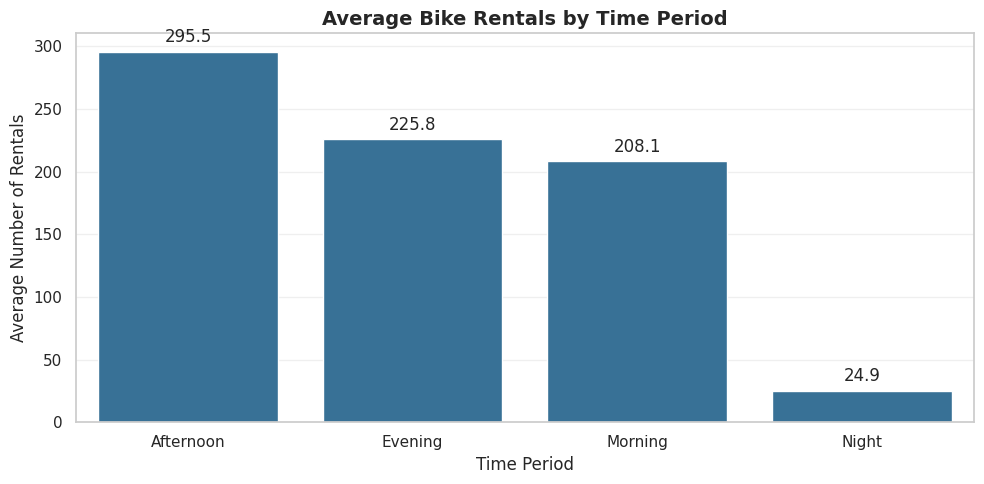

In [38]:
# Visualisasi periode waktu
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=time_analysis,
    x='time_period',
    y='mean',
    color='#2874A6',
    order=time_analysis['time_period']
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=4)

plt.title(
    'Average Bike Rentals by Time Period',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Time Period')
plt.ylabel('Average Number of Rentals')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Menentukan periode tertinggi dah terendah
highest_period = time_analysis.loc[
    time_analysis['mean'].idxmax()
]

lowest_period = time_analysis.loc[
    time_analysis['mean'].idxmin()
]

print("Periode permintaan tertinggi:",
      highest_period['time_period'])

print("Rata-rata penyewaan tertinggi:",
      round(highest_period['mean'], 2))

print("\nPeriode permintaan terendah:",
      lowest_period['time_period'])

print("Rata-rata penyewaan terendah:",
      round(lowest_period['mean'], 2))

Periode permintaan tertinggi: Afternoon
Rata-rata penyewaan tertinggi: 295.48

Periode permintaan terendah: Night
Rata-rata penyewaan terendah: 24.91


# Hasil Binning Berdasarkan Periode Waktu
Teknik binning diterapkan dengan membagi data penyewaan berdasarkan jam ke dalam empat periode, yaitu Night, Morning, Afternoon, dan Evening. Didapatkan kesimpulan bahwa periode permintaan tertinggi yaitu pada waktu Afternoon dengan rata-rata penyewaan tertinggi sebesar 295.48. Lalu diketahui juga periose permintaan terendah yaitu pada waktu Night dengan rata rata penyewaan sebesar 24.91

### 7.2 Manual Grouping: Kategori Tingkat Permintaan Harian
Tujuan: Mengelompokkan hari berdasarkan jumlah penyewaan sepeda untuk mengetahui karakteristik hari dengan permintaan rendah, sedang, dan tinggi.


In [40]:
# Mengitung total penyewaan harian
daily_rentals = df.groupby(
    'dteday'
)['cnt'].sum().reset_index()

daily_rentals.columns = [
    'date',
    'total_rentals'
]

daily_rentals.head()

,date,total_rentals
0,2011-01-01,985
1,2011-01-02,801
2,2011-01-03,1349
3,2011-01-04,1562
4,2011-01-05,1600


In [41]:
# Menentukan batas kategori permintaan
low_limit = daily_rentals['total_rentals'].quantile(0.33)
high_limit = daily_rentals['total_rentals'].quantile(0.67)

print("Batas permintaan rendah:", low_limit)
print("Batas permintaan tinggi:", high_limit)

Batas permintaan rendah: 3716.2
Batas permintaan tinggi: 5319.4


In [42]:
# Melakukan manual grouping tingkat permintaan harian
def categorize_demand(total):
    if total <= low_limit:
        return 'Low Demand'
    elif total <= high_limit:
        return 'Medium Demand'
    else:
        return 'High Demand'

daily_rentals['demand_category'] = (
    daily_rentals['total_rentals'].apply(categorize_demand)
)

daily_rentals.head(10)

,date,total_rentals,demand_category
0,2011-01-01,985,Low Demand
1,2011-01-02,801,Low Demand
2,2011-01-03,1349,Low Demand
3,2011-01-04,1562,Low Demand
4,2011-01-05,1600,Low Demand
5,2011-01-06,1606,Low Demand
6,2011-01-07,1510,Low Demand
7,2011-01-08,959,Low Demand
8,2011-01-09,822,Low Demand
9,2011-01-10,1321,Low Demand


In [43]:
# Menghitung jumlah hari dan rata-rata penyewaan
demand_analysis = daily_rentals.groupby(
    'demand_category',
    observed=False
).agg(
    total_days=('date', 'count'),
    average_rentals=('total_rentals', 'mean'),
    minimum_rentals=('total_rentals', 'min'),
    maximum_rentals=('total_rentals', 'max')
).reset_index()

demand_analysis

,demand_category,total_days,average_rentals,minimum_rentals,maximum_rentals
0,High Demand,241,6699.078838,5323,8714
1,Low Demand,241,2294.439834,22,3709
2,Medium Demand,249,4519.040161,3717,5319


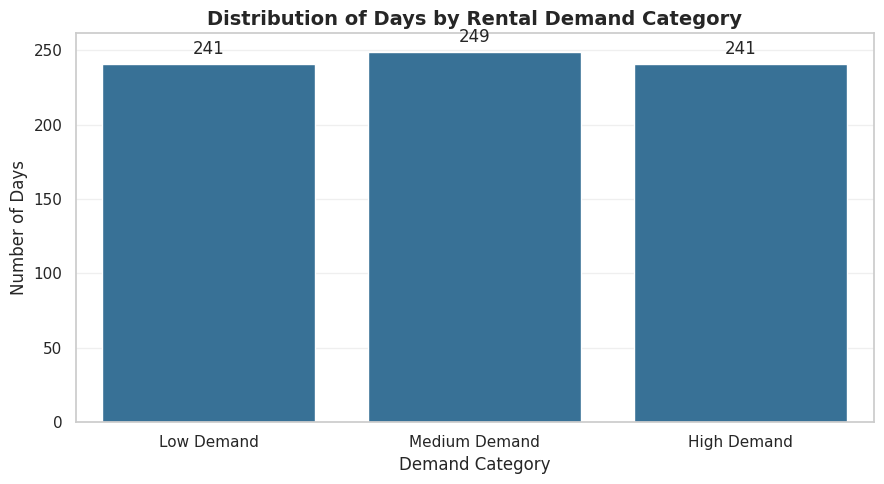

In [44]:
demand_order = [
    'Low Demand',
    'Medium Demand',
    'High Demand'
]

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=demand_analysis,
    x='demand_category',
    y='total_days',
    order=demand_order,
    color='#2874A6'
)

for container in ax.containers:
    ax.bar_label(container, padding=4)

plt.title(
    'Distribution of Days by Rental Demand Category',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Demand Category')
plt.ylabel('Number of Days')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Hasil Manual Grouping Berdasarkan Tingkat Permintaan
Manual grouping dilakukan dengan mengelompokkan total penyewaan sepeda harian ke dalam tiga kategori, yaitu Low Demand, Medium Demand, dan High Demand.Batas kategori ditentukan berdasarkan persentil ke-33 dan ke-67 dari distribusi total penyewaan harian. Dapat disimpulkan bahwa terdapat 241 hari untuk low demand, 249 hari untuk medium demand, dan 241 hari untuk high demand.

### 7.3 Rangkuman Advanced Analysis
Berdasarkan analisis lanjutan yang telah dilakukan, diperoleh dua pendekatan utama:

1. Binning berdasarkan periode waktu: Mengelompokkan data penyewaan sepeda berdasarkan jam ke dalam empat periode waktu, yaitu Night, Morning, Afternoon, dan Evening. Hasil analisis menunjukkan bahwa periode dengan rata-rata penyewaan tertinggi adalah Afternoon, yaitu sebesar 295,48 penyewaan. Sementara itu, rata-rata penyewaan terendah terjadi pada periode Night, yaitu sebesar 24,91 penyewaan.

2. Manual grouping berdasarkan tingkat permintaan harian: Mengelompokkan total penyewaan sepeda harian ke dalam tiga kategori, yaitu Low Demand, Medium Demand, dan High Demand. Penentuan kategori dilakukan berdasarkan persentil ke-33 dan ke-67 dari distribusi total penyewaan harian. Hasil pengelompokan menunjukkan bahwa terdapat 241 hari dalam kategori Low Demand, 249 hari dalam kategori Medium Demand, dan 241 hari dalam kategori High Demand.

Kedua pendekatan tersebut memberikan gambaran tambahan mengenai karakteristik permintaan penyewaan sepeda, baik berdasarkan periode waktu maupun tingkat permintaan harian.

# 8. Conclusion dan Recmmendation
Kesimpulan disusun berdasarkan hasil Exploratory Data Analysis (EDA), Visualization & Explanatory Analysis, serta Advanced Analysis. Analisis dilakukan untuk mengetahui karakteristik pengguna, pola penyewaan berdasarkan waktu, pengaruh kondisi cuaca, perubahan permintaan berdasarkan musim dan bulan, serta pengelompokan tingkat permintaan penyewaan sepeda.

### 8.1 Conclusion
Berdasarkan hasil analisis yang telah dilakukan, diperoleh beberapa kesimpulan untuk menjawab tiga pertanyaan bisnis yang telah ditentukan.

**1. Bagaimana pola rata-rata jumlah penyewaan sepeda per jam pada hari kerja dan hari non-kerja selama Januari 2011–Desember 2012, serta pada jam berapa permintaan mencapai puncaknya?** Berdasarkan hasil analisis, diketahui bahwa pola penyewaan sepeda memiliki perbedaan antara hari kerja (working day) dan hari non-kerja (non-working day). Pada hari kerja, permintaan penyewaan tertinggi terjadi pada pukul 17.00, dengan rata-rata sekitar 461,45 penyewaan. Pola penyewaan pada hari kerja juga menunjukkan peningkatan pada pagi hari, khususnya sekitar pukul 08.00. Hal ini mengindikasikan bahwa sepeda berpotensi banyak digunakan untuk mendukung aktivitas masyarakat saat berangkat dan pulang kerja. Sementara itu, pada hari non-kerja, permintaan cenderung meningkat sejak pagi hari dan mencapai puncaknya sekitar pukul 13.00. Berbeda dengan hari kerja yang memiliki pola peningkatan pada pagi dan sore hari, penyewaan pada hari non-kerja lebih terkonsentrasi pada siang hari. Hasil perbandingan berdasarkan jenis hari juga menunjukkan bahwa rata-rata penyewaan pada working day mencapai 193,21, lebih tinggi dibandingkan non-working day sebesar 181,41.

Dengan demikian, dapat disimpulkan bahwa waktu dan jenis hari memiliki keterkaitan dengan pola permintaan penyewaan sepeda. Permintaan pada hari kerja cenderung meningkat pada jam berangkat dan pulang kerja, sedangkan pada hari non-kerja lebih tinggi pada siang hari.

**2. Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kategori kondisi cuaca selama Januari 2011–Desember 2012?** Berdasarkan hasil analisis, diketahui bahwa rata-rata jumlah penyewaan sepeda berbeda pada setiap kategori kondisi cuaca. Kondisi Clear / Partly Cloudy memiliki rata-rata penyewaan tertinggi, yaitu sebesar 204,87 sepeda, dengan total penyewaan sebanyak 2.338.173. Pada kondisi Mist / Cloudy, rata-rata penyewaan mencapai 175,17 sepeda. Jumlah tersebut mengalami penurunan pada kondisi Light Rain / Snow, dengan rata-rata sebesar 111,58 sepeda. Sementara itu, kondisi Heavy Rain / Snow memiliki rata-rata penyewaan terendah, yaitu sebesar 74,33 sepeda. Namun, kategori ini hanya memiliki 3 pengamatan sehingga hasilnya perlu diinterpretasikan secara hati-hati.

Hasil tersebut menunjukkan adanya kecenderungan bahwa semakin buruk kondisi cuaca, semakin rendah rata-rata jumlah penyewaan sepeda. Dengan demikian, kondisi cuaca merupakan salah satu faktor yang berkaitan dengan perubahan permintaan layanan penyewaan sepeda.

**3. Bagaimana perubahan rata-rata jumlah penyewaan sepeda berdasarkan musim dan bulan selama Januari 2011–Desember 2012, serta periode apa yang menunjukkan permintaan tertinggi dan terendah?** Berdasarkan hasil analisis musim, diketahui bahwa rata-rata penyewaan sepeda tertinggi terjadi pada musim Fall, yaitu sebesar 236,02 sepeda. Selanjutnya, musim Summer memiliki rata-rata sebesar 208,34 sepeda, Winter sebesar 198,87 sepeda, dan Spring memiliki rata-rata terendah sebesar 111,11 sepeda. Berdasarkan analisis bulanan, rata-rata penyewaan tertinggi terjadi pada September, yaitu sebesar 240,77 sepeda. Sementara itu, Januari menjadi bulan dengan rata-rata penyewaan terendah, yaitu sebesar 94,42 sepeda. Pola bulanan menunjukkan bahwa permintaan penyewaan cenderung meningkat sejak Januari hingga Juni, sedikit menurun pada Juli, kemudian kembali meningkat hingga mencapai puncaknya pada September. Setelah itu, permintaan mulai mengalami penurunan hingga Desember.

Dengan demikian, dapat disimpulkan bahwa terdapat pola musiman dalam aktivitas penyewaan sepeda. Periode pertengahan hingga akhir tahun, khususnya sekitar Juni sampai September, menunjukkan tingkat permintaan yang relatif tinggi, sedangkan awal tahun menunjukkan permintaan yang lebih rendah.

**4. Bagaimana karakteristik permintaan penyewaan sepeda berdasarkan periode waktu dan kategori tingkat permintaan harian?** Berdasarkan hasil Advanced Analysis, dilakukan dua pendekatan tambahan, yaitu binning berdasarkan periode waktu dan manual grouping berdasarkan tingkat permintaan harian. Hasil binning menunjukkan bahwa periode Afternoon memiliki rata-rata penyewaan tertinggi, yaitu sebesar 295,48 sepeda. Sebaliknya, periode Night memiliki rata-rata penyewaan terendah, yaitu sebesar 24,91 sepeda. Hasil ini menunjukkan bahwa aktivitas penyewaan lebih banyak terjadi pada siang hingga sore hari dibandingkan malam hari. Sementara itu, hasil manual grouping mengelompokkan total penyewaan harian ke dalam tiga kategori berdasarkan persentil ke-33 dan ke-67, yaitu Low Demand, Medium Demand, dan High Demand. Hasil pengelompokan menunjukkan terdapat 241 hari dalam kategori Low Demand, 249 hari dalam kategori Medium Demand, dan 241 hari dalam kategori High Demand.

Dengan demikian, analisis lanjutan memberikan gambaran mengenai distribusi permintaan berdasarkan periode waktu dan tingkat permintaan harian. Hasil ini dapat membantu pengelola dalam mengidentifikasi waktu serta hari yang membutuhkan perhatian lebih dalam pengelolaan ketersediaan armada.


### 8.2 Recommendation
**1. Mengoptimalkan ketersediaan sepeda berdasarkan jam dan jenis hari.**
Pengelola layanan disarankan untuk menyesuaikan distribusi dan ketersediaan sepeda berdasarkan pola permintaan pada hari kerja dan hari non-kerja.
- Pada hari kerja, ketersediaan sepeda perlu ditingkatkan menjelang pukul 08.00 dan terutama pukul 17.00 karena kedua waktu tersebut menunjukkan peningkatan permintaan.
- Pada hari non-kerja, pengelola dapat memprioritaskan ketersediaan sepeda menjelang siang hingga pukul 13.00.
- Pengelola juga dapat melakukan pemantauan jumlah sepeda pada setiap lokasi penyewaan agar kebutuhan pengguna pada jam sibuk dapat terpenuhi.

**2. Menyesuaikan perencanaan operasional berdasarkan kondisi cuaca**
Hasil analisis menunjukkan bahwa rata-rata penyewaan pada cuaca cerah atau sedikit berawan mencapai 204,87, sedangkan pada kondisi hujan deras atau salju lebat hanya sebesar 74,33.
Berdasarkan temuan tersebut, pengelola dapat:
- Mempersiapkan ketersediaan armada yang lebih besar ketika kondisi cuaca diperkirakan cerah.
- Menyesuaikan kebutuhan operasional ketika terjadi hujan atau kondisi cuaca buruk karena permintaan cenderung menurun.
- Memanfaatkan informasi prakiraan cuaca sebagai salah satu pertimbangan dalam memperkirakan kebutuhan penyewaan harian.

**3. Menyusun strategi ketersediaan armada berdasarkan musim dan bulan**
Hasil analisis menunjukkan bahwa musim Fall memiliki rata-rata penyewaan tertinggi sebesar 236,02, sedangkan bulan September menjadi bulan dengan permintaan tertinggi sebesar 240,77.
Oleh karena itu, pengelola disarankan untuk:
- Mempersiapkan ketersediaan sepeda lebih banyak menjelang periode dengan permintaan tinggi, khususnya Juni hingga September.
- Melakukan pemeriksaan dan pemeliharaan armada sebelum memasuki periode dengan tingkat permintaan tinggi.
- Menyesuaikan jumlah sepeda yang dioperasikan pada awal tahun, khususnya Januari, ketika rata-rata penyewaan relatif rendah.
- Menggunakan pola permintaan bulanan sebagai dasar perencanaan kebutuhan armada untuk periode berikutnya.

**4. Menerapkan strategi operasional berdasarkan periode waktu**
Berdasarkan hasil binning, periode Afternoon memiliki rata-rata penyewaan tertinggi sebesar 295,48, sedangkan periode Night memiliki rata-rata terendah sebesar 24,91.
Dengan demikian, pengelola dapat:
- Memprioritaskan kesiapan armada dan distribusi sepeda sebelum memasuki periode Afternoon.
- Mengoptimalkan proses pengembalian dan pendistribusian ulang sepeda agar ketersediaan armada tetap terjaga pada jam dengan permintaan tinggi.
- Melakukan penyesuaian aktivitas operasional pada periode Night karena tingkat permintaan relatif lebih rendah.

**5. Menggunakan kategori permintaan harian untuk perencanaan operasional**
Hasil manual grouping menunjukkan bahwa terdapat 241 hari dengan kategori Low Demand, 249 hari dengan kategori Medium Demand, dan 241 hari dengan kategori High Demand.
Berdasarkan hasil tersebut, pengelola dapat menerapkan strategi yang berbeda untuk setiap kategori:
- Low Demand: Melakukan penyesuaian jumlah armada yang disediakan dan memanfaatkan periode ini untuk kegiatan pemeliharaan serta pemeriksaan sepeda.
- Medium Demand: Menjaga ketersediaan armada pada tingkat normal serta memastikan proses penyewaan dan pengembalian berjalan dengan baik.
- High Demand: Meningkatkan kesiapan armada, memastikan sepeda tersedia dalam jumlah cukup, serta memperhatikan distribusi sepeda pada lokasi dengan permintaan tinggi.
Pengelompokan ini dapat membantu pengelola dalam menyusun perencanaan operasional yang lebih terstruktur sesuai dengan tingkat permintaan harian.

**6. Melakukan evaluasi dan pemantauan permintaan secara berkala**
Pengelola disarankan untuk melakukan evaluasi terhadap data penyewaan secara berkala agar strategi operasional tetap sesuai dengan perubahan kebutuhan pengguna.
Evaluasi dapat dilakukan dengan memperhatikan beberapa aspek berikut:
- Perubahan rata-rata penyewaan berdasarkan jam dan jenis hari.
- Perubahan permintaan berdasarkan kondisi cuaca.
- Perkembangan pola penyewaan berdasarkan musim dan bulan.
- Perubahan jumlah hari dalam kategori Low Demand, Medium Demand, dan High Demand.
- Perbandingan jumlah pengguna casual dan registered untuk memahami karakteristik pengguna layanan.
Dengan pemantauan tersebut, pengelola dapat mengidentifikasi perubahan pola permintaan lebih awal dan melakukan penyesuaian strategi operasional berdasarkan kondisi aktual.

# 9. Dashboard Data Preparation


In [45]:
import pandas as pd

df = pd.read_csv('hour.csv')

print("Ukuran dataset:", df.shape)
print("\nKolom dataset:")
print(df.columns.tolist())

display(df.head())

Ukuran dataset: (17379, 17)

Kolom dataset:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [46]:
import pandas as pd

df = pd.read_csv('hour.csv')
main_data = df.copy()

main_data['date'] = pd.to_datetime(main_data['dteday'])
main_data['hour'] = main_data['hr']

season_mapping = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}
main_data['season_name'] = main_data['season'].map(season_mapping)

weather_mapping = {
    1: 'Clear',
    2: 'Mist',
    3: 'Light Rain/Snow',
    4: 'Heavy Rain/Snow'
}
main_data['weather_name'] = main_data['weathersit'].map(weather_mapping)

main_data['total_rentals'] = main_data['cnt']

main_data.to_csv('main_data.csv', index=False)

print("main_data.csv berhasil dibuat!")
print("Ukuran dataset:", main_data.shape)

display(main_data.head())

main_data.csv berhasil dibuat!
Ukuran dataset: (17379, 22)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,date,hour,season_name,weather_name,total_rentals
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01,0,Spring,Clear,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01,1,Spring,Clear,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01,2,Spring,Clear,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01,3,Spring,Clear,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01,4,Spring,Clear,1


In [47]:
from google.colab import files

files.download('main_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>